## Exploratory Data analysis

### Project description

Zomato Restaurant Analysis (Hyderabad): Exploratory Data Analysis

This project analyzes Zomato data for about 105 restaurants and roughly 10,000 customer reviews, almost all in the Gachibowli area of Hyderabad. It uses Python (pandas, matplotlib, seaborn).

What it covers

-Data cleaning: fixing missing values, converting ratings, costs and review dates to proper types, and creating new features such as locality, reviewer review and follower counts, and review length.

-Rating analysis: the distribution of ratings (average about 3.6 out of 5) and the top 10 restaurants by average rating, counting only those with more than 20 reviews. AB’s Absolute Barbecues (4.88), B-Dubs (4.81) and 3B’s (4.76) lead the list.

-Cuisine analysis: the 10 most common cuisines on the platform.

-Cost vs. rating: a scatter plot with a trend line to check whether pricier restaurants are rated higher.

-Sentiment analysis: a keyword-based positive/negative score for each review.

-Time trend: how the average rating changes month by month.

In [ ]:
# Importing Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Loading Dataset

In [3]:
df_restraunat_names_and_metadata=pd.read_csv('Zomato_Restaurant_names_and_Metadata.csv')

df_restraunt_reviews=pd.read_csv('Zomato_Restaurant_reviews.csv')
df_restraunat_names_and_metadata.head(10)



,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."
5,The Fisherman's Wharf,https://www.zomato.com/hyderabad/the-fisherman...,"1,500","Sunday Brunches, Corporate Favorites, Great Bu...","Seafood, Goan, North Indian, Continental, Asian","12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30P..."
6,eat.fit,https://www.zomato.com/hyderabad/eat-fit-gachi...,500,Food Hygiene Rated Restaurants in Hyderabad,"Healthy Food, North Indian, Continental, South...",7 AM to 10 PM
7,Shah Ghouse Spl Shawarma,https://www.zomato.com/hyderabad/shah-ghouse-s...,300,NaN,Lebanese,12 Noon to 12 Midnight
8,Hyper Local,https://www.zomato.com/hyderabad/hyper-local-g...,"1,000","Great Buffets, Live Sports Screenings, Best Ba...","American, Chinese, North Indian, Kebab, South ...",12 Noon to 12 Midnight
9,Cream Stone,https://www.zomato.com/hyderabad/cream-stone-g...,350,Frozen Delights,"Ice Cream, Desserts","10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri..."


In [4]:
df_restraunt_reviews.shape
df_restraunat_names_and_metadata.shape

(105, 6)

In [5]:
# Checking null values
print(df_restraunt_reviews.isnull().sum())
print()

print(df_restraunat_names_and_metadata.isnull().sum())
print()

Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64



In [6]:
df_restraunt_reviews.dtypes

Restaurant    object
Reviewer      object
Review        object
Rating        object
Metadata      object
Time          object
Pictures       int64
dtype: object

In [7]:
#Changing Rating type to numeric
df_restraunt_reviews['Rating']=pd.to_numeric(df_restraunt_reviews['Rating'], errors='coerce')

df_restraunt_reviews=df_restraunt_reviews.dropna(subset=['Review','Rating'], how='all')

df_restraunt_reviews['Rating']=df_restraunt_reviews['Rating'].fillna(df_restraunt_reviews['Rating'].mean())



In [8]:
df_restraunat_names_and_metadata['Collections']=df_restraunat_names_and_metadata['Collections'].fillna('None')
df_restraunat_names_and_metadata['Timings']=df_restraunat_names_and_metadata['Timings'].fillna('Not available')


In [9]:
df_restraunt_reviews['Metadata']=df_restraunt_reviews['Metadata'].fillna('N/A')
df_restraunt_reviews['Time']=df_restraunt_reviews['Time'].fillna('N/A')
df_restraunt_reviews.isnull().sum()

Restaurant    0
Reviewer      0
Review        7
Rating        0
Metadata      0
Time          0
Pictures      0
dtype: int64

In [10]:
df_restraunt_reviews.value_counts().sum()

9955

In [11]:
df_restraunat_names_and_metadata['Cost']=df_restraunat_names_and_metadata['Cost'].str.replace(',','',regex=False).astype(float)
df_restraunat_names_and_metadata['Cost'].dtypes

dtype('float64')

In [12]:
# Converting Time into datetime
df_restraunt_reviews['Time']=pd.to_datetime(df_restraunt_reviews['Time'], errors='coerce')

In [13]:
df_restraunt_reviews.columns

Index(['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time',
       'Pictures'],
      dtype='object')

In [14]:
def extract_locality(url):
    path = url.split('.com/')[-1].strip('/')
    if '/' not in path:
        return 'Unspecified'
    return path.split('/')[-1].split('-')[-1].title()

df_restraunat_names_and_metadata['Locality'] = df_restraunat_names_and_metadata['Links'].apply(extract_locality)


extracted = df_restraunt_reviews['Metadata'].str.extract(r'(?P<Reviewer_Reviews>\d+)\s*Reviews?(?:\s*,\s*(?P<Reviewer_Followers>\d+)\s*Followers?)?')
df_restraunt_reviews['Reviewer_Reviews'] = pd.to_numeric(extracted['Reviewer_Reviews'], errors='coerce').fillna(0)
df_restraunt_reviews['Reviewer_Followers'] = pd.to_numeric(extracted['Reviewer_Followers'], errors='coerce').fillna(0)


df_restraunt_reviews['Review_Length'] = df_restraunt_reviews['Review'].fillna('').str.split().str.len()

print(df_restraunat_names_and_metadata[['Name', 'Cost', 'Locality']].head())
print()
print(df_restraunt_reviews[['Restaurant', 'Rating', 'Reviewer_Reviews', 'Reviewer_Followers', 'Review_Length']].head())


                             Name    Cost    Locality
0                 Beyond Flavours   800.0  Gachibowli
1                        Paradise   800.0  Gachibowli
2                        Flechazo  1300.0  Gachibowli
3  Shah Ghouse Hotel & Restaurant   800.0  Gachibowli
4      Over The Moon Brew Company  1200.0  Gachibowli

        Restaurant  Rating  Reviewer_Reviews  Reviewer_Followers  \
0  Beyond Flavours     5.0               1.0                 2.0   
1  Beyond Flavours     5.0               3.0                 2.0   
2  Beyond Flavours     5.0               2.0                 3.0   
3  Beyond Flavours     5.0               1.0                 1.0   
4  Beyond Flavours     5.0               3.0                 2.0   

   Review_Length  
0             41  
1             27  
2             31  
3             28  
4             27  


In [15]:
# EDA BASIC DATA ANALYSIS

print(df_restraunt_reviews[['Rating', 'Reviewer_Reviews', 'Reviewer_Followers', 'Review_Length', 'Pictures']].describe())

            Rating  Reviewer_Reviews  Reviewer_Followers  Review_Length  \
count  9962.000000       9962.000000         9962.000000    9962.000000   
mean      3.601044         23.944891          161.864686      50.137824   
std       1.483387         50.589786          617.741092      60.776901   
min       1.000000          0.000000            0.000000       0.000000   
25%       3.000000          1.000000            1.000000      24.000000   
50%       4.000000          4.000000            7.000000      34.000000   
75%       5.000000         22.000000           63.000000      58.000000   
max       5.000000       1031.000000        13410.000000     964.000000   

          Pictures  
count  9962.000000  
mean      0.751456  
std       2.574863  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       0.000000  
max      64.000000  


### Rating Distribution

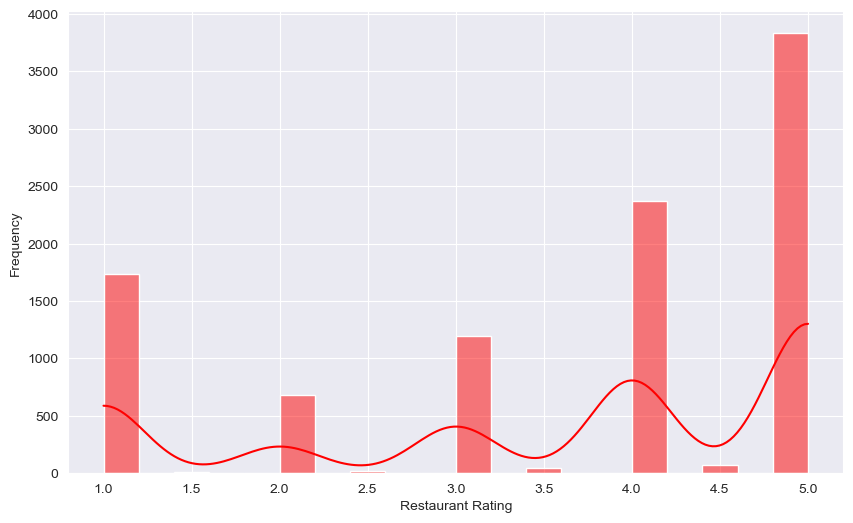

In [16]:
plt.figure(figsize=(10,6))
sns.histplot(df_restraunt_reviews['Rating'], bins=20, color='red',kde=True)
plt.xlabel('Restaurant Rating')
plt.ylabel('Frequency')
plt.show()

In [17]:
review_counts=df_restraunt_reviews.groupby('Restaurant')['Rating'].count()
qualified_review=review_counts[review_counts>20].index

top_rated=(df_restraunt_reviews[df_restraunt_reviews['Restaurant'].isin(qualified_review)].groupby('Restaurant')['Rating'].mean().sort_values(ascending=False).head(10))

### Restaurant Rating

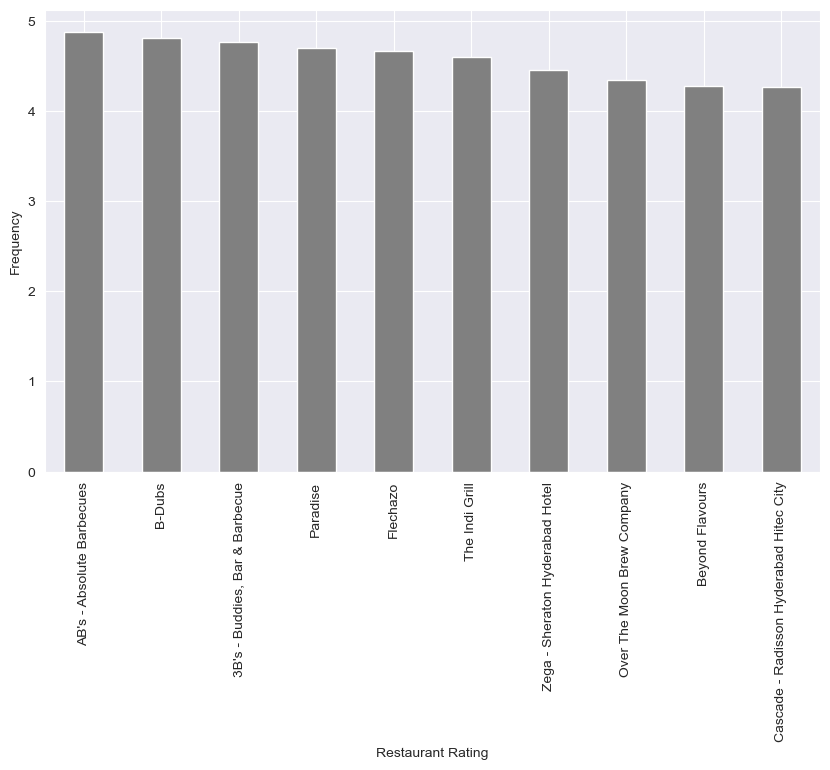

Restaurant
AB's - Absolute Barbecues                  4.88
B-Dubs                                     4.81
3B's - Buddies, Bar & Barbecue             4.76
Paradise                                   4.70
Flechazo                                   4.66
The Indi Grill                             4.60
Zega - Sheraton Hyderabad Hotel            4.45
Over The Moon Brew Company                 4.34
Beyond Flavours                            4.28
Cascade - Radisson Hyderabad Hitec City    4.26
Name: Rating, dtype: float64


In [18]:
plt.figure(figsize=(10,6))
top_rated.plot(kind='bar', color='grey')
plt.xlabel('Restaurant Rating')
plt.ylabel('Frequency')
plt.xticks(rotation=90)
plt.show()

print(top_rated)

### Top 10 Cuisine

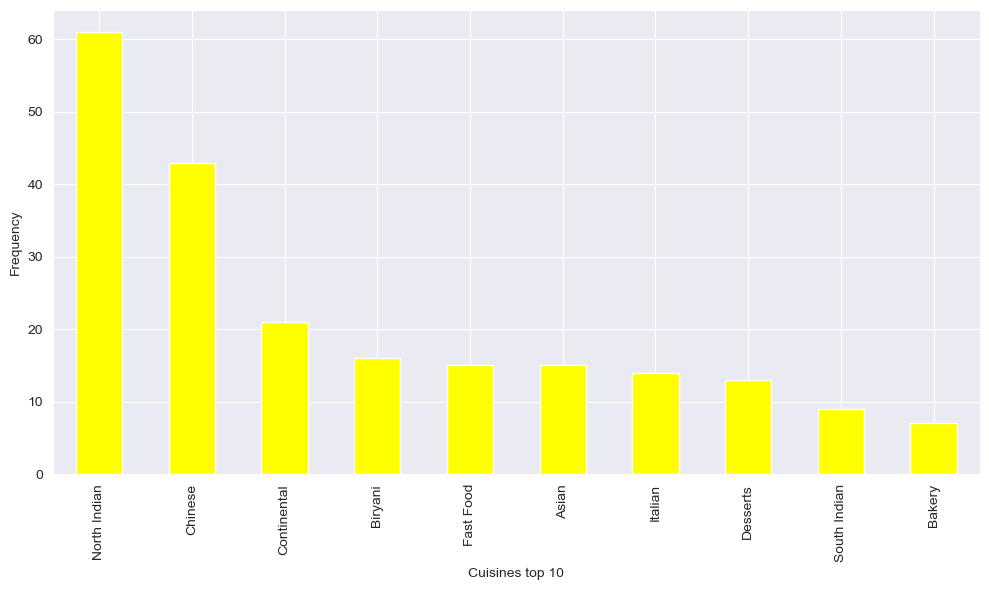

In [19]:
cuisine_series=df_restraunat_names_and_metadata['Cuisines'].dropna().str.split(',').explode().str.strip()
cuisine_count=cuisine_series.value_counts().head(10)

plt.figure(figsize=(10,6))
cuisine_count.plot(kind='bar', color='yellow')
plt.xlabel('Cuisines top 10')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


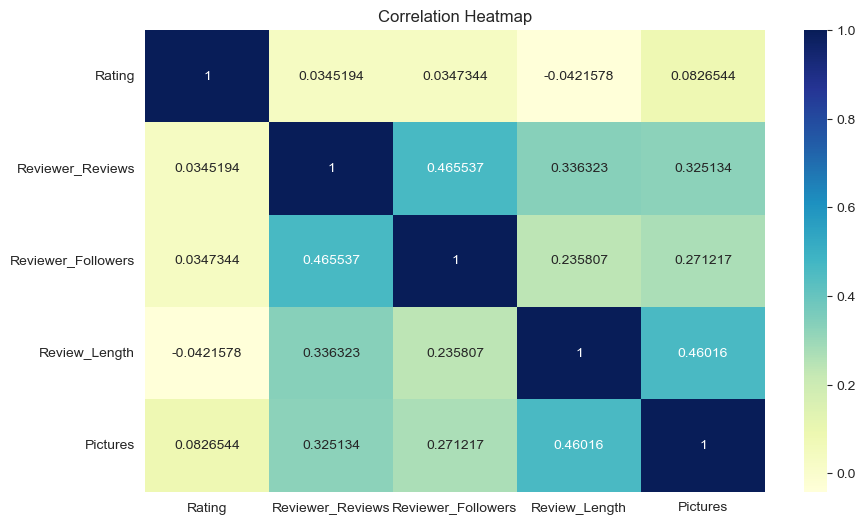

Rating                1.000000
Pictures              0.082654
Reviewer_Followers    0.034734
Reviewer_Reviews      0.034519
Review_Length        -0.042158
Name: Rating, dtype: float64


In [20]:
numeric_cols=df_restraunt_reviews[['Rating', 'Reviewer_Reviews', 'Reviewer_Followers', 'Review_Length', 'Pictures']]

corelation=numeric_cols.corr()

plt.figure(figsize=(10,6))
sns.heatmap(corelation, annot=True, cmap='YlGnBu', fmt='g')
plt.title('Correlation Heatmap')
plt.show()

print(corelation['Rating'].sort_values(ascending=False))


In [21]:
locality=df_restraunat_names_and_metadata['Locality'].value_counts()
print(locality)
print(f"{locality.iloc[0]} of {len(df_restraunat_names_and_metadata)} are in {locality.index[0]}")

Locality
Gachibowli     104
Unspecified      1
Name: count, dtype: int64
104 of 105 are in Gachibowli


### Advance analysis

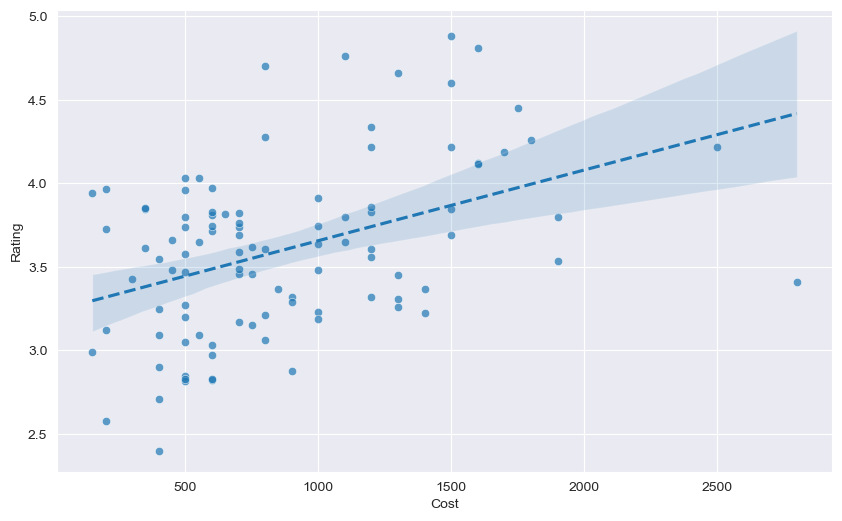

In [22]:
import seaborn as sns
avg_rating=df_restraunt_reviews.groupby('Restaurant')['Rating'].mean().reset_index()
merged=df_restraunat_names_and_metadata.merge(avg_rating, how='left', left_on='Name' ,right_on='Restaurant')

plt.figure(figsize=(10,6))
sns.scatterplot(x='Cost', y='Rating', data=merged, alpha=0.7)
sns.regplot(x='Cost', y='Rating', data=merged, scatter=False, line_kws={'linestyle':'--'})
plt.xlabel("Cost" )
plt.ylabel("Rating")
plt.show()

In [23]:
df_restraunt_reviews['Review']

0       The ambience was good, food was quite good . h...
1       Ambience is too good for a pleasant evening. S...
2       A must try.. great food great ambience. Thnx f...
3       Soumen das and Arun was a great guy. Only beca...
4       Food is good.we ordered Kodi drumsticks and ba...
                              ...                        
9995    Madhumathi Mahajan Well to start with nice cou...
9996    This place has never disappointed us.. The foo...
9997    Bad rating is mainly because of "Chicken Bone ...
9998    I personally love and prefer Chinese Food. Had...
9999    Checked in here to try some delicious chinese ...
Name: Review, Length: 9962, dtype: object

SENTIMENT ANALYSIS

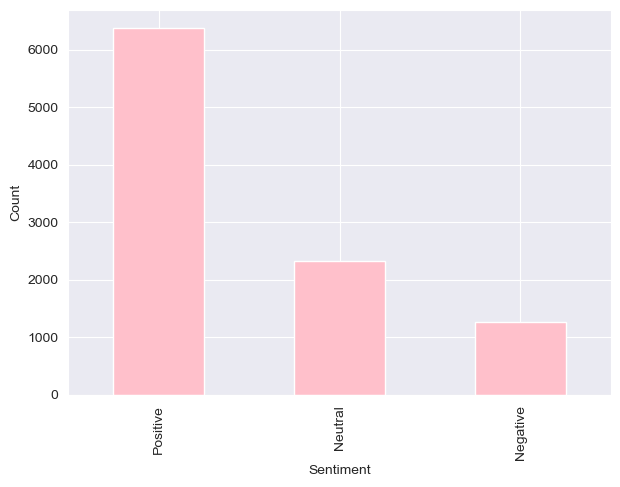

In [24]:
positive_words = {'good','great','excellent','amazing','awesome','delicious','best','love','loved',
                   'nice','tasty','fresh','friendly','perfect','recommend','fantastic','wonderful',
                   'enjoyed','favorite','yummy','superb','happy','beautiful','quick','polite'}
negative_words = {'bad','worst','terrible','poor','slow','rude','disappointing','disappointed','cold',
                   'awful','horrible','waste','never','bland','overpriced','dirty','stale','average',
                   'mediocre','late','wrong','unhygienic','worse','soggy','tasteless'}


def score_sentiment(text):
    if not isinstance(text, str):
        return 'Neutral'
    words=set(text.lower().replace(',',' ').replace(',',' ').split())
    pos=len(words & positive_words)
    neg=len(words & negative_words)

    if pos>neg:
        return 'Positive'
    elif neg>pos:
        return 'Negative'
    else:
        return 'Neutral'

df_restraunt_reviews['Sentiment']=df_restraunt_reviews['Review'].apply(score_sentiment)

plt.figure(figsize=(7,5))
df_restraunt_reviews['Sentiment'].value_counts().plot(kind='bar',color='pink')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()


TIME BASED ANALYSIS

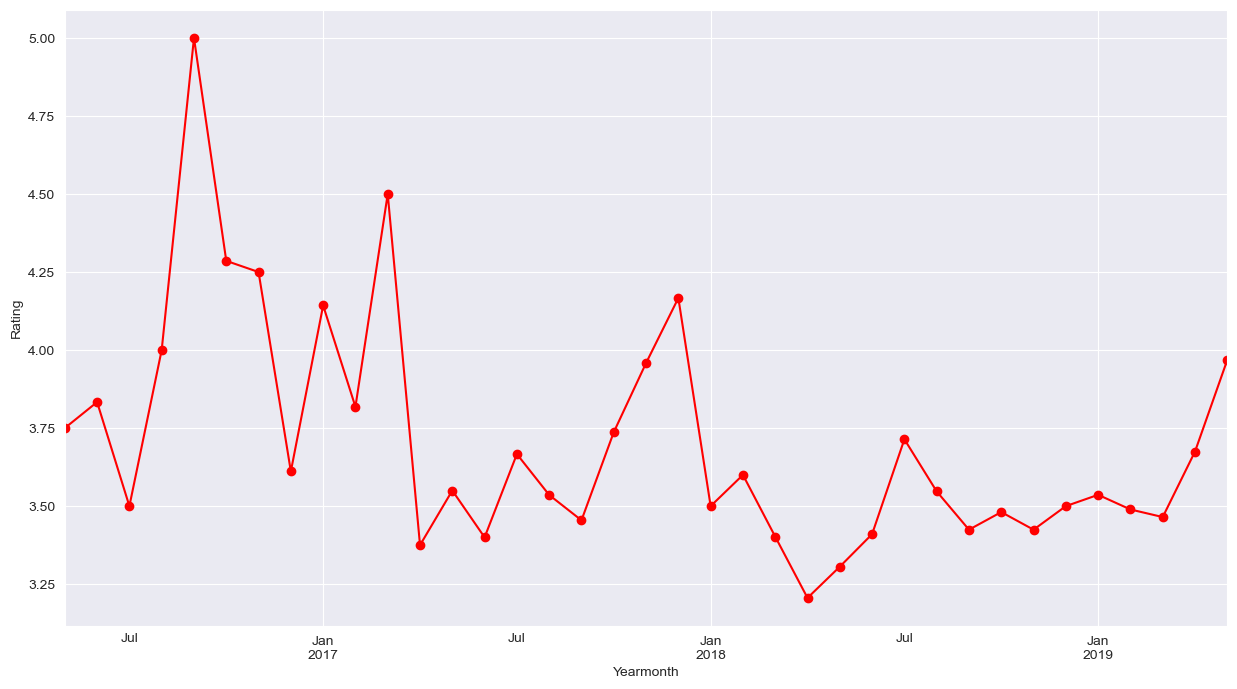

In [25]:
df_restraunt_reviews['Yearmonth']=df_restraunt_reviews['Time'].dt.to_period('M')
monthly_rating=df_restraunt_reviews.groupby('Yearmonth')['Rating'].mean()

plt.figure(figsize=(15,8))
monthly_rating.plot(kind='line',marker='o', color='red')
plt.xlabel('Yearmonth')
plt.ylabel('Rating')
plt.show()